In [ ]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.supervised.trees import DecisionTree
from LearnML.learn_about.learn_about import learn_about_DecisionTree
from LearnML.selection.split import train_test_split
from LearnML.metrics.metrics import classification_report

Path added: /home/mo/Documents/LearnML_Library


Decision Trees are a non-parametric supervised learning method used for both classification and regression tasks. The goal is to create a model that predicts the value of a target variable by learning simple decision rules inferred from the data features. A tree can be seen as a piecewise constant approximation.

Key Concepts:
1. Model Representation: A tree consists of internal decision nodes (feature thresholds) and leaf nodes (final predictions). Samples traverse left if they satisfy the condition (e.g., feature <= threshold) and right otherwise.
2. Impurity Criteria: The tree evaluates split quality using measures like Gini Impurity or Entropy for classification, or Variance Reduction for regression.
3. Best Split Search: At each node, the algorithm greedily searches through all features and candidate thresholds to maximize Information Gain (impurity reduction).
4. Recursive Partitioning: The dataset is split into smaller subsets, and the process repeats recursively on each subset 

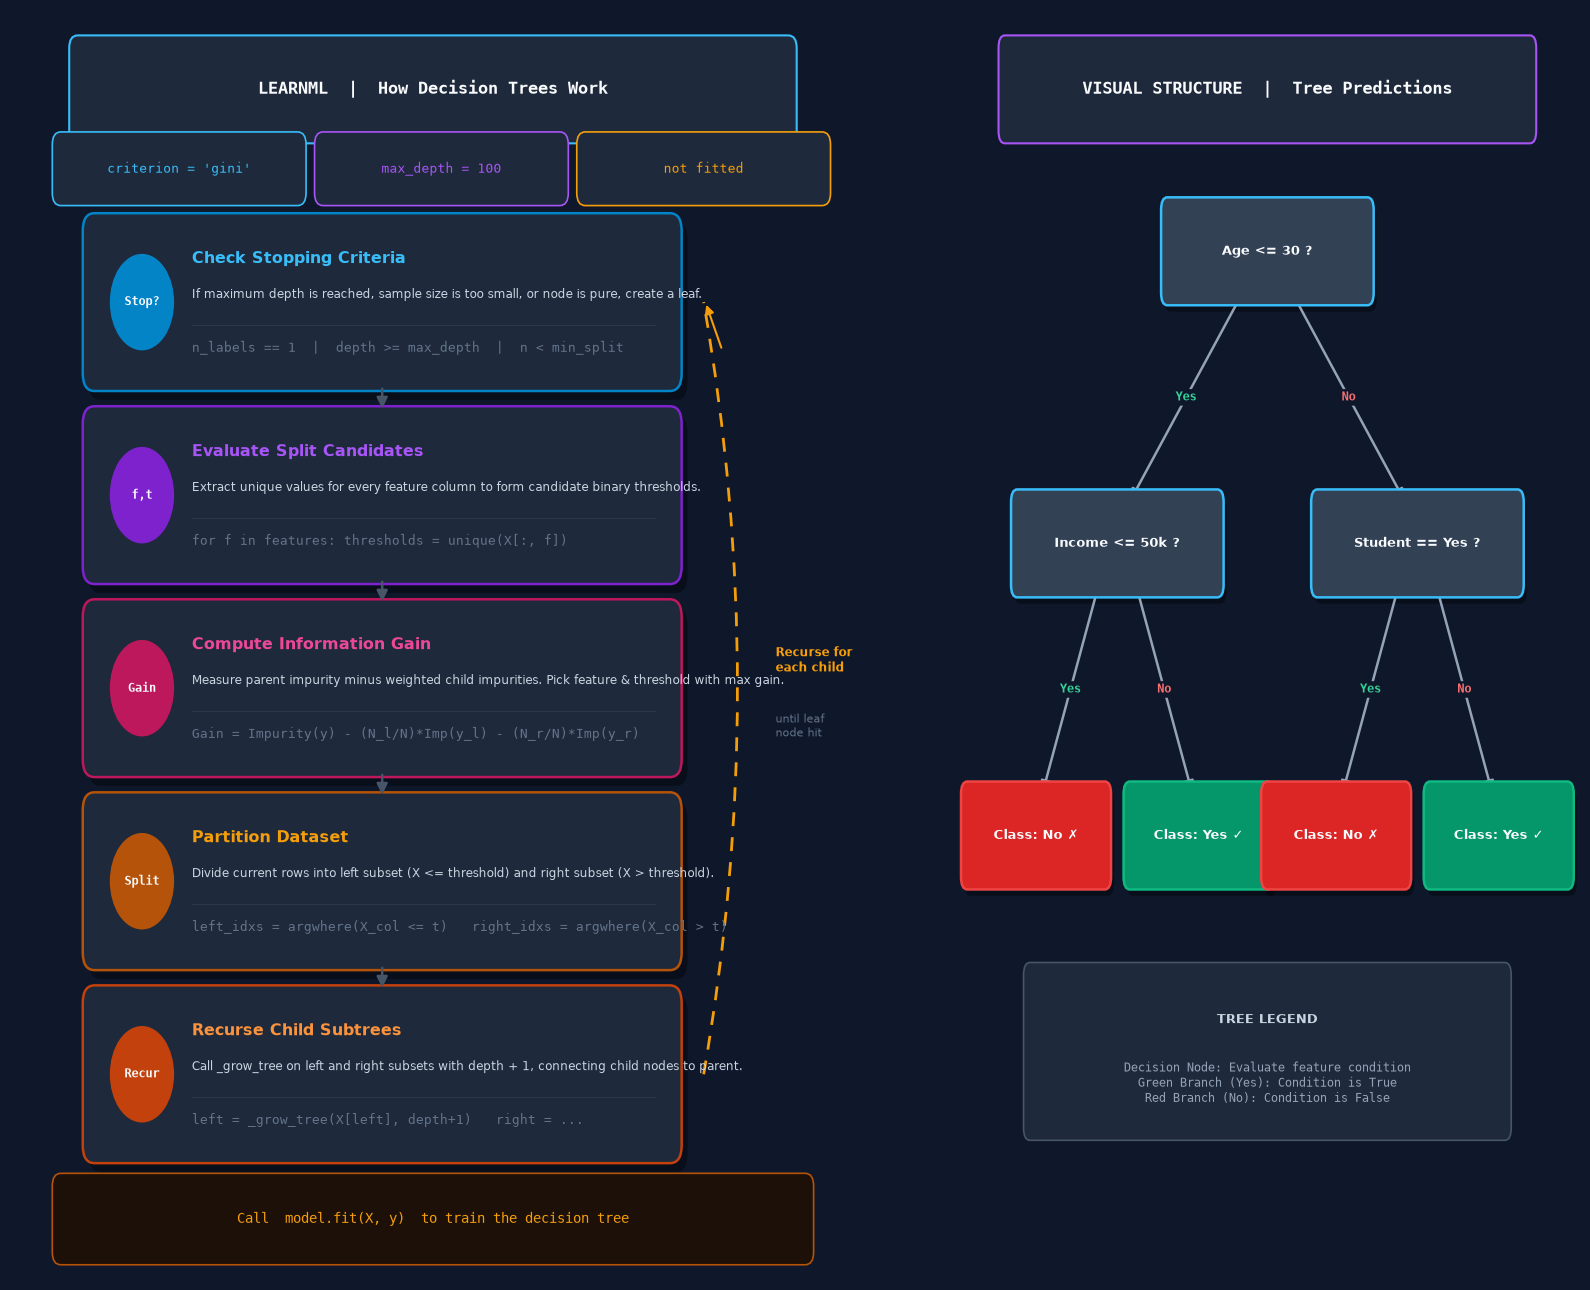

In [2]:
learn_about_DecisionTree()

In [3]:
from sklearn.datasets import make_classification


##1. Generate synthetic classification data (70% informative features)
X, y = make_classification(
    n_samples=1000,         # Total number of rows/samples
    n_features=10,          # Total number of input features
    n_informative=7,        # 70% pure informative features (7 out of 10)
    n_redundant=2,          # 20% redundant features (linear combinations)
    # Note: Remaining 1 feature (10%) is automatically pure random noise
    n_classes=3,            # Number of target categories (e.g., 0, 1, 2)
    n_clusters_per_class=1, # Complexity of each class distribution
    weights=[0.5, 0.3, 0.2],# Class balance (50%, 30%, 20%)
    flip_y=0.02,            # Add 2% random label noise (set to 0.0 for 100% clean labels)
    random_state=42         # Seed for reproducible results
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)




Text(0.5, 1.0, 'Training Data Distribution')

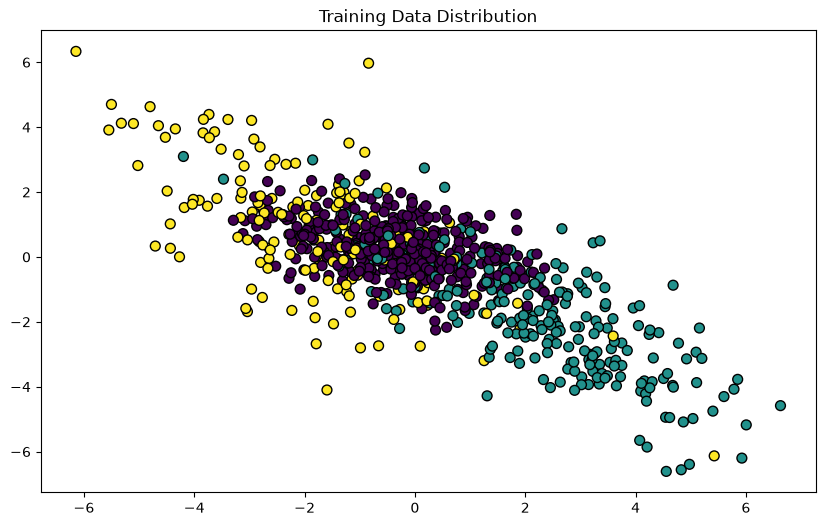

In [4]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     


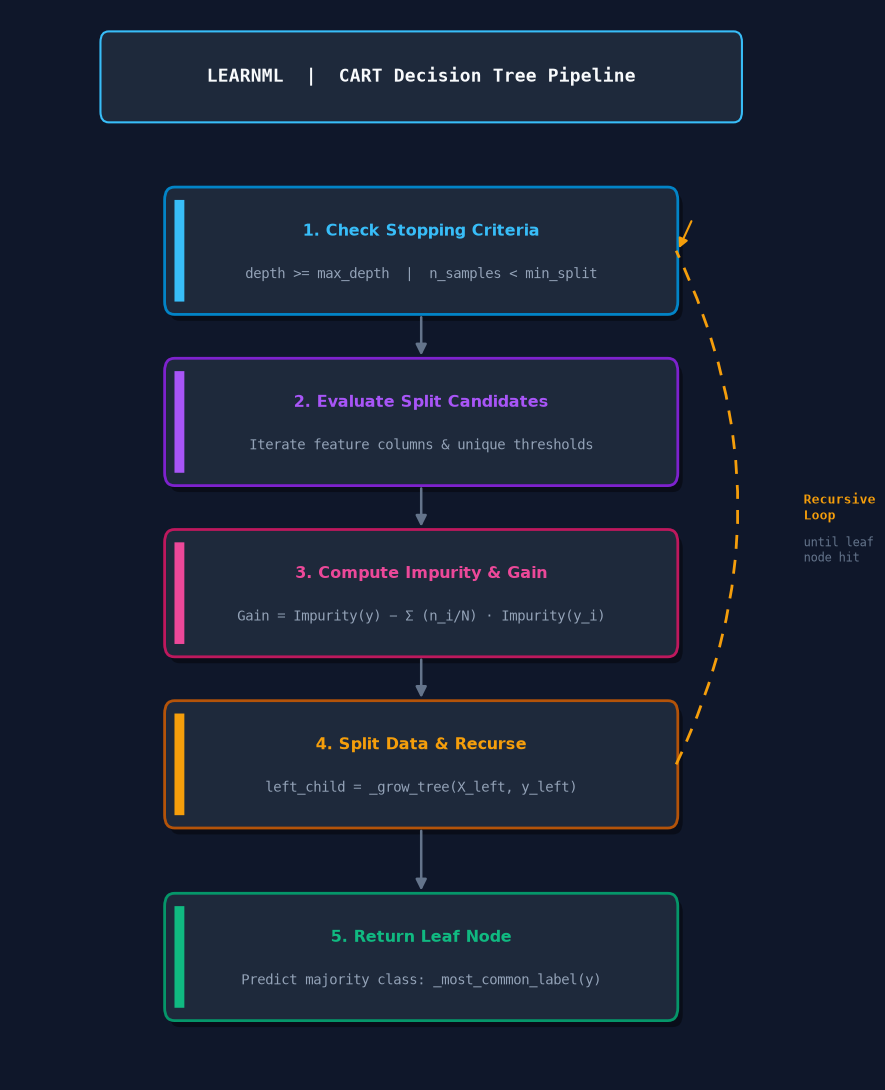

In [5]:
tree_model=DecisionTree(max_depth=5, min_samples_split=10 , criterion='gini')
tree_model.fit(X_train, y_train)

In [6]:
predictions= tree_model.predict(X_test)

In [7]:
predictions

array([2, 0, 0, 0, 0, 2, 0, 2, 2, 0, 1, 1, 0, 0, 2, 0, 1, 0, 1, 0, 0, 0,
       2, 0, 1, 1, 0, 0, 0, 0, 0, 0, 2, 1, 1, 0, 1, 1, 2, 0, 0, 1, 0, 0,
       2, 0, 2, 0, 1, 2, 0, 1, 0, 1, 2, 0, 0, 0, 0, 0, 1, 1, 2, 1, 1, 0,
       1, 1, 0, 1, 0, 2, 0, 0, 1, 2, 0, 0, 1, 2, 0, 2, 0, 2, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 1, 0, 0, 0, 2, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 2, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 2, 1, 0, 0, 0, 0, 0, 2, 0, 1, 1, 1, 1, 2, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 2, 0, 0, 2, 1, 0, 0, 0, 0, 0, 2, 2, 1, 2, 0, 0, 1, 0,
       2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 2, 1, 0, 2, 2, 0, 0,
       2, 2])

In [8]:
print(classification_report(y_test , tree_model.predict(X_test)))

Accuracy: 0.815
Precision: 0.9130434782608695
Recall: 0.75
F1 Score: 0.8235294117647057
None


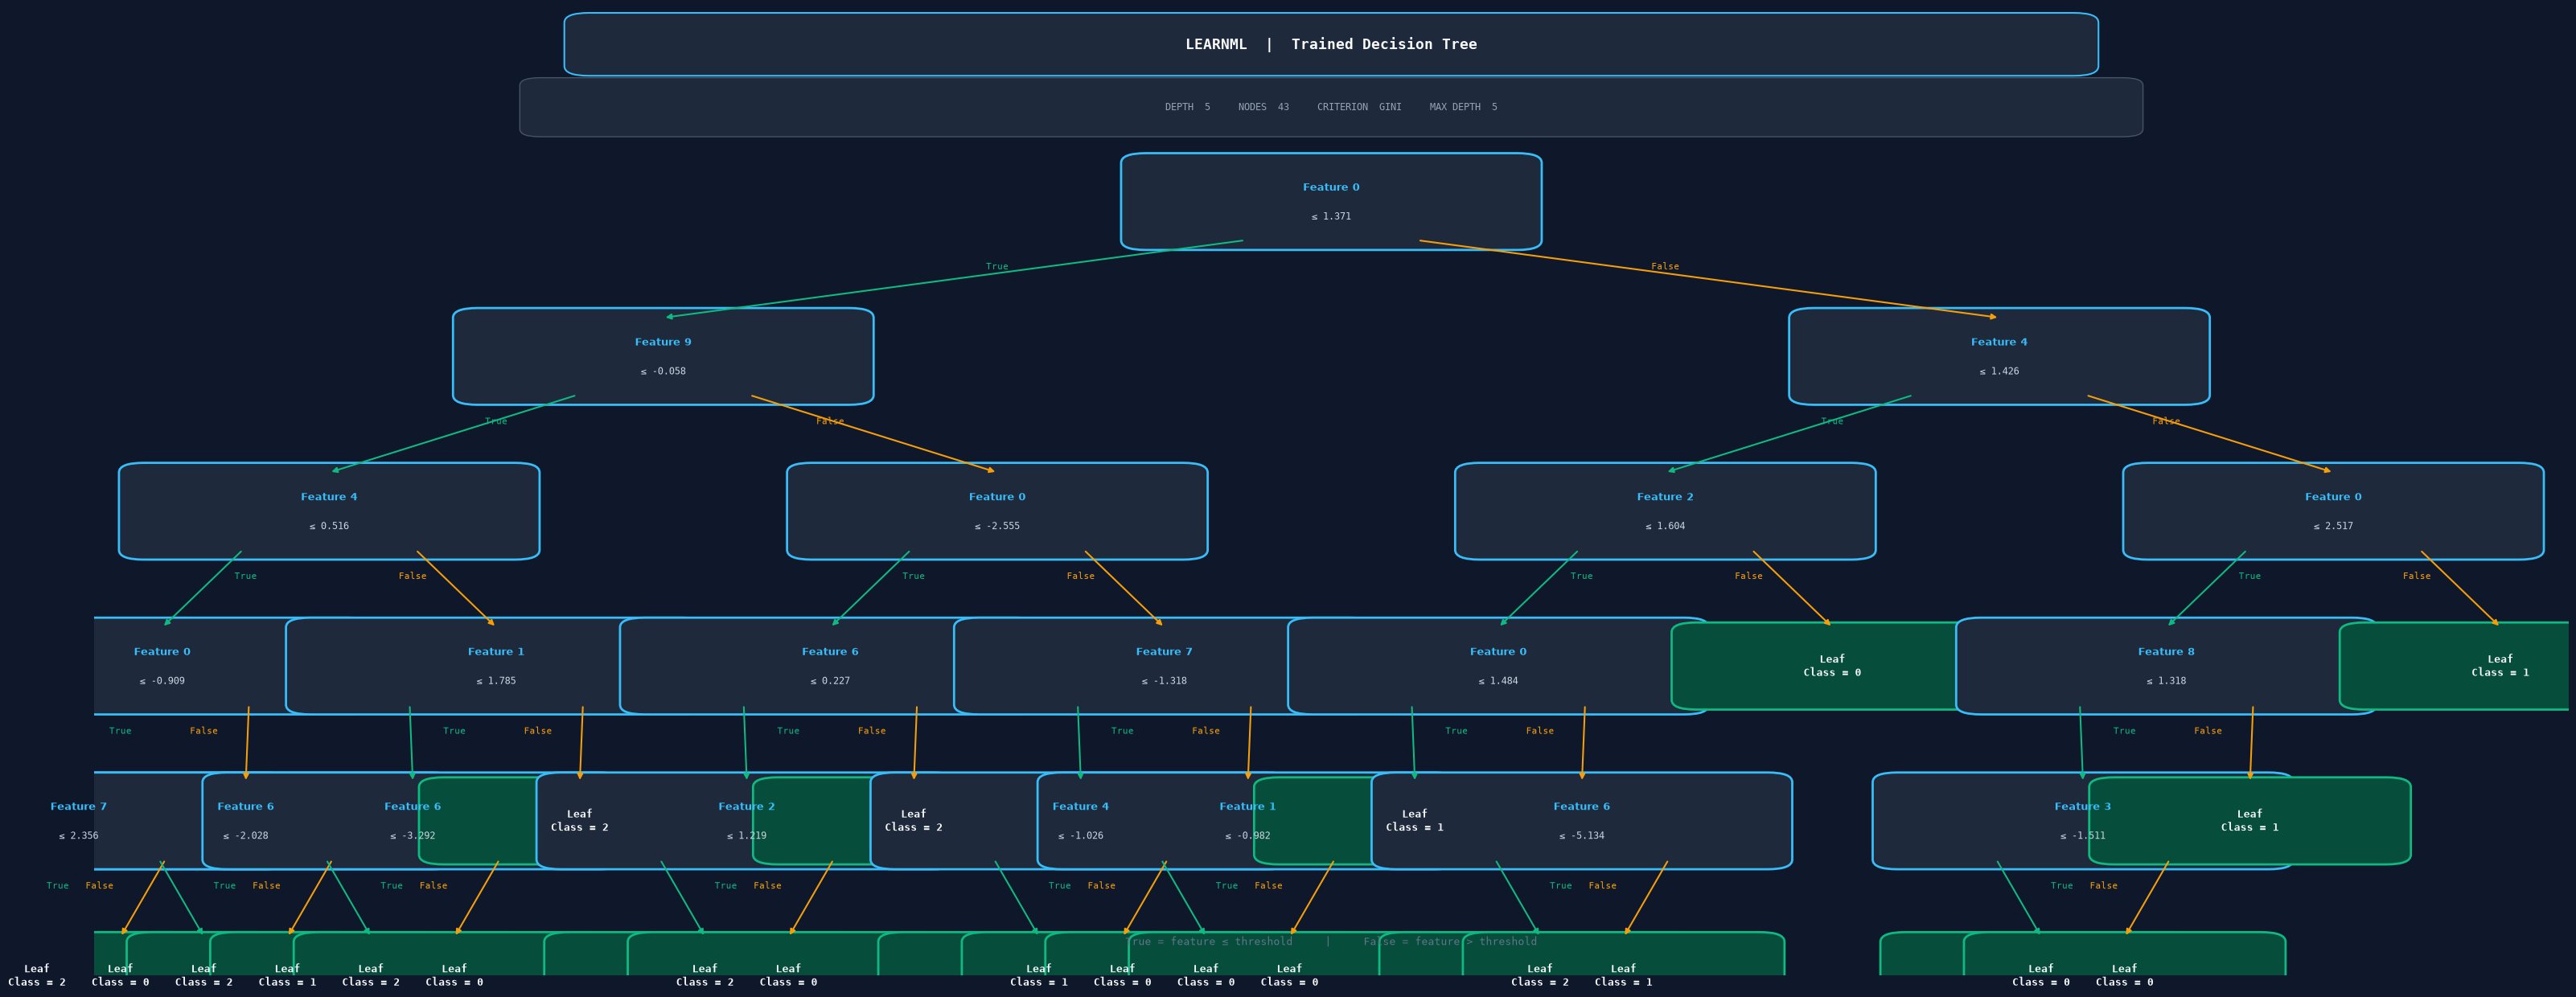

In [9]:
tree_model.visualize()